## Island Restriction and Threat Status

Hypothesis Test: Is island restriction associated with whether a bird species is threatened?

H₀: Island restriction and threat status are independent.
H₁: Island restriction and threat status are associated.

We use a chi-square test of independence with α = 0.05.

Threatened species include VU, EN, CR, CR (PE), and CR (PEW).

Non-threatened species include LC and NT. We exclude other or missing conservation statuses, as well as records that dont have a valid island classification.

The test uses species counts. We also compare the threatened percentage within each island group to describe the direction and size of the difference.

The included dataset contains 2,602 island-restricted species and 8,385 species not restricted to islands, so we compare threatened percentages within each group when interpreting and plotting the results to account for such size differences (makes such differences relative)

Because island restriction and threat status are both categorical variables, we use a chi-square test of independence on species counts.



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display

chi_filename = "BIRDBASE v2025.1 Sekercioglu et al. Final.xlsx"

chi_birds = pd.read_excel(
    chi_filename,
    sheet_name="Data",
    header=1
)

chi_birds = chi_birds[["ISL", "2024 IUCN Red List category"]].copy()

# Parse island classifications and clean conservation labels.
chi_birds["ISL"] = pd.to_numeric(chi_birds["ISL"], errors="coerce")

chi_status = chi_birds["2024 IUCN Red List category"].astype("string")
chi_status = chi_status.str.strip()

chi_status_groups = {
    "LC": "Non-threatened",
    "NT": "Non-threatened",
    "VU": "Threatened",
    "EN": "Threatened",
    "CR": "Threatened",
    "CR (PE)": "Threatened",
    "CR (PEW)": "Threatened"
}

chi_birds["Threat status"] = chi_status.map(chi_status_groups)

# Keep only records with usable classifications.
chi_analysis = chi_birds.dropna(subset=["Threat status"])

chi_valid_island = (
    (chi_analysis["ISL"] == 0) |
    (chi_analysis["ISL"] == 1)
)

chi_analysis = chi_analysis[chi_valid_island].copy()

chi_analysis["Island restriction"] = chi_analysis["ISL"].map({
    0: "Not island-restricted",
    1: "Island-restricted"
})

print("Original species:", len(chi_birds))
print("Included species:", len(chi_analysis))
print("Excluded species:", len(chi_birds) - len(chi_analysis))

display(chi_analysis.head())

Original species: 11589
Included species: 10987
Excluded species: 602


,ISL,2024 IUCN Red List category,Threat status,Island restriction
0,0,LC,Non-threatened,Not island-restricted
1,0,VU,Threatened,Not island-restricted
2,0,NT,Non-threatened,Not island-restricted
3,0,LC,Non-threatened,Not island-restricted
4,1,VU,Threatened,Island-restricted


In [3]:
chi_table = pd.crosstab(
    chi_analysis["Island restriction"],
    chi_analysis["Threat status"]
)

print("Observed species counts:")
display(chi_table)

# Both island groups and both threat categories must be present
if chi_table.shape != (2, 2):
    raise ValueError("The test requires both island groups and both threat categories.")

chi_alpha = 0.05

# Pearson chi-square without continuity correction
chi_statistic, chi_p_value, chi_dof, chi_expected = chi2_contingency(
    chi_table,
    correction=False
)

chi_expected_table = pd.DataFrame(
    chi_expected,
    index=chi_table.index,
    columns=chi_table.columns
)

print("Expected counts under independence:")
display(chi_expected_table.round(2))

if chi_expected.min() < 5:
    raise ValueError("An expected count is below 5. Review the test before interpreting it.")

print("Chi-square statistic:", chi_statistic)
print("Degrees of freedom:", chi_dof)
print("P-value:", chi_p_value)

if chi_p_value < chi_alpha:
    print("Reject H₀: evidence of an association between island restriction and threat status.")
else:
    print("Fail to reject H₀: insufficient evidence of an association.")

Observed species counts:


Threat status,Non-threatened,Threatened
Island restriction,,
Island-restricted,2003,599
Not island-restricted,7673,712


Expected counts under independence:


Threat status,Non-threatened,Threatened
Island restriction,,
Island-restricted,2291.52,310.48
Not island-restricted,7384.48,1000.52


Chi-square statistic: 398.9204243750173
Degrees of freedom: 1
P-value: 9.461183773467754e-89
Reject H₀: evidence of an association between island restriction and threat status.


In [4]:
chi_group_totals = chi_table.sum(axis=1)

chi_percentages = (
    chi_table["Threatened"] / chi_group_totals
) * 100

chi_summary = pd.DataFrame({
    "Total species": chi_group_totals,
    "Threatened species": chi_table["Threatened"],
    "Threatened (%)": chi_percentages
})

display(chi_summary.round(2))

chi_island_percent = chi_percentages.loc["Island-restricted"]
chi_other_percent = chi_percentages.loc["Not island-restricted"]

chi_difference = chi_island_percent - chi_other_percent

print(
    "Difference (island minus other):",
    round(chi_difference, 2),
    "percentage points"
)

,Total species,Threatened species,Threatened (%)
Island restriction,,,
Island-restricted,2602,599,23.02
Not island-restricted,8385,712,8.49


Difference (island minus other): 14.53 percentage points


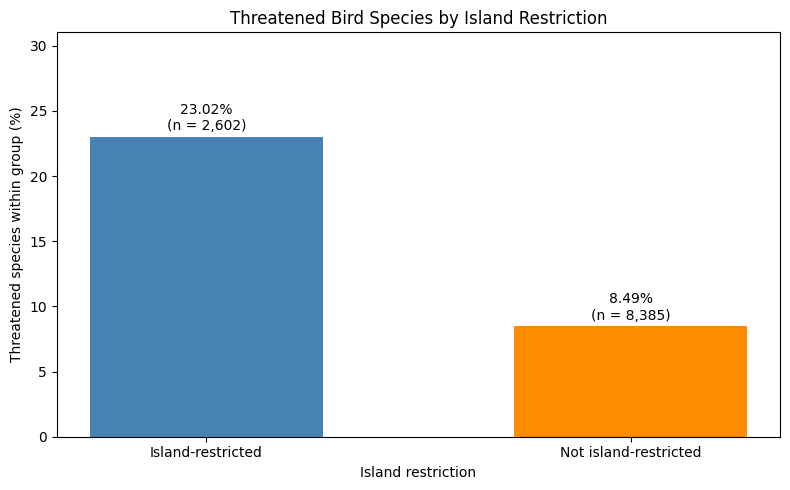

In [5]:
chi_plot_labels = ["Island-restricted", "Not island-restricted"]
chi_plot_values = [chi_island_percent, chi_other_percent]

plt.figure(figsize=(8, 5))

plt.bar(
    chi_plot_labels,
    chi_plot_values,
    color=["steelblue", "darkorange"],
    width=0.55
)

# Label each bar with its percentage and total number of species.
for chi_i in range(len(chi_plot_labels)):
    chi_group = chi_plot_labels[chi_i]
    chi_percent = chi_plot_values[chi_i]
    chi_total = chi_group_totals.loc[chi_group]

    plt.text(
        chi_i,
        chi_percent + 0.5,
        f"{chi_percent:.2f}%\n(n = {chi_total:,})",
        ha="center"
    )

plt.title("Threatened Bird Species by Island Restriction")
plt.xlabel("Island restriction")
plt.ylabel("Threatened species within group (%)")

plt.ylim(0, max(chi_plot_values) + 8)
plt.tight_layout()
plt.show()

## Conclusion

Among 10,987 included species, 23.02% of island-restricted species were threatened, compared with 8.49% of species not restricted to islands. The difference was 14.53 percentage points. This also means that the proportion of threatened species among island-restricted birds is about 2.7 times that among birds not restricted to islands.

All expected counts exceeded 5, supporting the use of the chi-square approximation. Hooray!

The chi-square test produced chi sqr statistic of 398.92, with 1 degree of freedom and p ≈ 9.46 × 10⁻⁸⁹. At α = 0.05, we reject the null hypothesis. This provides statistical evidence of an association between island restriction and threat status, with island-restricted species having a higher threatened proportion in the analyzed dataset.

This does not establish causation. Its results apply to the included species and depend on our conservation-status grouping and exclusions. Related species share evolutionary history, so the assumption of independent observations is not perfect.

### Relationship Between Bird Diet and Body Mass

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from IPython.display import display, Markdown

# Locate the BirdBase workbook
source_file = Path("BIRDBASE v2025.1 Sekercioglu et al. Final.xlsx")

# Upload the file if it is not already available
if not source_file.exists():
    from google.colab import files
    uploaded = files.upload()

    spreadsheets = [
        name for name in uploaded
        if name.lower().endswith(".xlsx")
    ]

    if not spreadsheets:
        raise FileNotFoundError(
            "Upload the BirdBase .xlsx workbook to continue."
        )

    source_file = Path(spreadsheets[0])

print(f"Using BirdBase source: {source_file.name}")

Using BirdBase source: BIRDBASE v2025.1 Sekercioglu et al. Final.xlsx


### Selecting the Relevant Variables

The BirdBase dataset contains numerous characteristics of bird species, but this analysis focuses only on diet and body mass.

We use the Average Mass column for bird weight and the dietary-weight columns for food composition.

The Excel Data sheet contains its actual field names in the second row, so we specify header=1 when importing.

In [8]:
# Columns representing different food groups
food_columns = [
    "IN-Wt", "FR-Wt", "NE-Wt", "SE-Wt", "VE-Wt",
    "FI-Wt", "SC-Wt", "PL-Wt", "MS-Wt"
]

# Food groups representing plant-based diets
plant_columns = [
    "FR-Wt",
    "NE-Wt",
    "SE-Wt",
    "PL-Wt"
]

# All relevant columns for the analysis
needed_columns = [
    "IOC 15.1",
    "Primary Diet",
    "Average Mass",
    *food_columns,
    "SUM-Wt",
    "Diet_Lit"
]

# Read the Data sheet from BirdBase
raw = pd.read_excel(
    source_file,
    sheet_name="Data",
    header=1,
    usecols=needed_columns,
    engine="openpyxl"
)

# Rename the species identifier column
raw = raw.rename(
    columns={"IOC 15.1": "Species ID"}
)

print(
    f"Imported {len(raw):,} species "
    f"with {len(raw.columns)} relevant fields."
)

# Preview the relevant data
display(
    raw[
        [
            "Species ID",
            "Primary Diet",
            "Average Mass",
            "FR-Wt",
            "PL-Wt",
            "SUM-Wt"
        ]
    ].head()
)

Imported 11,589 species with 14 relevant fields.


,Species ID,Primary Diet,Average Mass,FR-Wt,PL-Wt,SUM-Wt
0,1,Herbivore,114500.0,0,5,10.0
1,6,Herbivore,107875.0,0,5,10.0
2,8,Plant,25250.0,0.06,9.01,10.0
3,14,Plant,21925.0,T,9.4,10.0
4,18,Invertebrate,2602.5,T,T,10.0


## 2. Data Preprocessing

Pearson's correlation coefficient measures the linear relationship between two numerical variables.

However, the Primary Diet column in BirdBase contains categorical labels such as Fruit, Invertebrate, and Omnivore.

Because these categories cannot be meaningfully assigned arbitrary numerical values, we instead use the numeric dietary weights supplied by BirdBase.

**Diet variable:**
Plant-food diet score = FR-Wt + NE-Wt + SE-Wt + PL-Wt

- FR-Wt: Fruit
- NE-Wt: Nectar
- SE-Wt: Seeds
- PL-Wt: Other plant materials

The total dietary score is normally 10 for known diets. A higher plant-food score indicates a larger plant-food component.

**Weight variable:**
Average Mass, measured in grams.

Because bird body masses vary dramatically between species, we apply a log10 transformation to average mass.

We also:
- Convert numeric columns to appropriate data types.
- Treat trace dietary weights marked T as zero scored weight.
- Remove invalid or missing data.
- Keep only published dietary records (Diet_Lit = 1).
- Verify that dietary weights add up correctly.

The resulting analysis will compare plant-food diet score against log10 average mass.

In [9]:
data = raw.copy()

# BirdBase uses 'T' for trace dietary items.
# These contribute zero to the numeric weight score.
for col in food_columns:
    cleaned_text = (
        data[col]
        .astype("string")
        .str.strip()
        .replace({"T": "0", "t": "0"})
    )

    data[col] = pd.to_numeric(
        cleaned_text,
        errors="coerce"
    )

# Convert relevant columns to numeric values
for col in ["Average Mass", "SUM-Wt", "Diet_Lit"]:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

# Verify the sum of dietary weights
data["checked_diet_sum"] = data[food_columns].sum(
    axis=1,
    min_count=len(food_columns)
)

# Filter for valid observations
valid_rows = (
    data["Diet_Lit"].eq(1)
    & data["Average Mass"].gt(0)
    & data["SUM-Wt"].gt(0)
    & data[food_columns].notna().all(axis=1)
    & data[food_columns].ge(0).all(axis=1)
    & data[food_columns].le(10).all(axis=1)
    & np.isclose(data["SUM-Wt"], 10, atol=1e-6)
    & np.isclose(
        data["checked_diet_sum"],
        data["SUM-Wt"],
        atol=1e-6
    )
)

#keep only valid rows
analysis = data.loc[valid_rows].copy()

#calculate plant-based diet score
analysis["plant_diet_score"] = (
    analysis[plant_columns].sum(axis=1)
)

#calculate log10 body mass
analysis["log10_mass_g"] = np.log10(
    analysis["Average Mass"]
)

#verify that enough observations exist
if (
    len(analysis) < 3
    or analysis["plant_diet_score"].nunique() < 2
):
    raise ValueError(
        "Too few valid species records for Pearson's correlation."
    )

print(f"Rows in original workbook: {len(raw):,}")

print(
    "Rows retained for Pearson's analysis: "
    f"{len(analysis):,}"
)

print(
    f"Rows excluded: {len(raw) - len(analysis):,}"
)

#preview
display(
    analysis[
        [
            "Species ID",
            "Primary Diet",
            "Average Mass",
            "plant_diet_score",
            "log10_mass_g"
        ]
    ].head(8)
)

Rows in original workbook: 11,589
Rows retained for Pearson's analysis: 9,361
Rows excluded: 2,228


,Species ID,Primary Diet,Average Mass,plant_diet_score,log10_mass_g
0,1,Herbivore,114500.00,8.0,5.058805
1,6,Herbivore,107875.00,8.0,5.032921
2,8,Plant,25250.00,9.96,4.402261
3,14,Plant,21925.00,10.0,4.340940
4,18,Invertebrate,2602.50,0.0,3.415391
5,21,Invertebrate,2602.50,0.0,3.415391
7,24,Invertebrate,1296.50,2.0,3.112773
8,25,Invertebrate,2156.25,2.0,3.333699


## Pearson's Correlation Coefficient

We use Pearson's correlation coefficient to determine whether bird diet and body mass have a statistically significant linear relationship.

Our variables are:

- X: Plant-food diet score (0–10)
- Y: Log10 of average body mass in grams

### Hypotheses

**Null Hypothesis (H0):**
There is no linear correlation between plant-food diet score and log-transformed body mass.

H0: ρ = 0

**Alternative Hypothesis (H1):**
There is a nonzero linear correlation between plant-food diet score and log-transformed body mass.

H1: ρ ≠ 0

### Significance Level

α = 0.05.

If p < 0.05, we reject the null hypothesis.

If p ≥ 0.05, we fail to reject the null hypothesis.

Pearson's r ranges from -1 to +1, where values closer to zero indicate weaker linear relationships.

In [10]:
#two numerical variables
x = analysis["plant_diet_score"].to_numpy(
    dtype=float
)

y = analysis["log10_mass_g"].to_numpy(
    dtype=float
)

#calculate Pearson's correlation coefficient
r, p_value = pearsonr(x, y)

#number of observations
n = len(analysis)

alpha = 0.05

#display
print(
    "Pearson correlation: plant-food diet score "
    "vs log10 average mass"
)

print(f"n                 = {n:,} species")
print(f"Pearson r         = {r:.6f}")
print(f"Two-sided p-value = {p_value:.4g}")

print(
    f"Significance      = "
    f"{'p < 0.05: reject H0' if p_value < alpha else 'p >= 0.05: do not reject H0'}"
)

Pearson correlation: plant-food diet score vs log10 average mass
n                 = 9,361 species
Pearson r         = 0.050293
Two-sided p-value = 1.125e-06
Significance      = p < 0.05: reject H0


## Visualization

We use a scatterplot to visualize the relationship between
plant-food diet score and bird body mass.

- X-axis: Plant-food diet score (0–10)
- Y-axis: Log10 average body mass in grams
- Gray dots: Individual bird species
- Black line: Line of best fit

The transparency of the dots helps display overlapping observations.

The line of best fit helps illustrate the direction of the
linear relationship between the two variables.

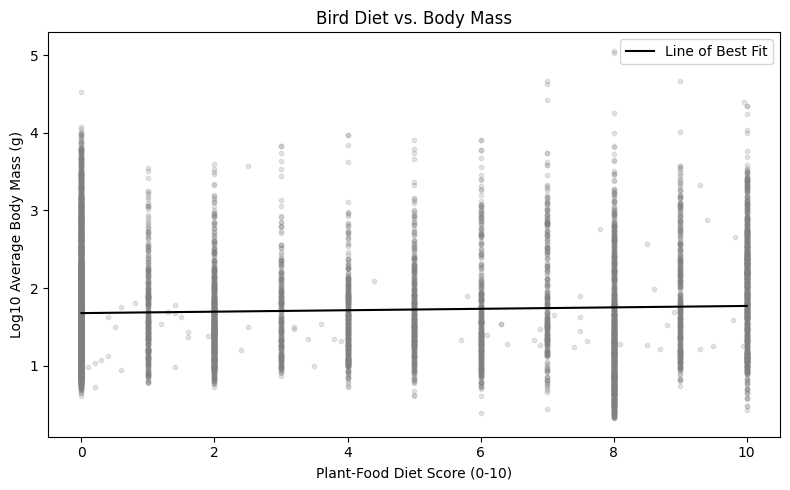

In [14]:
import numpy as np
import matplotlib.pyplot as plt

#select variables from cleaned data
x = analysis["plant_diet_score"]
y = analysis["log10_mass_g"]

#create scatterplot
plt.figure(figsize=(8, 5))

plt.scatter(
    x,
    y,
    color="gray",
    alpha=0.2,
    s=10
)

#calculate line of best fit
slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

#regression line
plt.plot(
    x_line,
    y_line,
    color="black",
    label="Line of Best Fit"
)

plt.xlabel("Plant-Food Diet Score (0-10)")
plt.ylabel("Log10 Average Body Mass (g)")
plt.title("Bird Diet vs. Body Mass")

plt.legend()
plt.tight_layout()
plt.show()

## Pearson Correlation Conclusion

We interpret the Pearson correlation coefficient and p-value to determine whether the relationship between plant-food diet score and body mass is statistically significant.

This represents one of the three statistical conclusions required for Checkpoint 2.

In [12]:
#strength of correlation
if abs(r) < 0.10:
    magnitude = "negligible (extremely weak)"
elif abs(r) < 0.30:
    magnitude = "weak"
elif abs(r) < 0.50:
    magnitude = "moderate"
else:
    magnitude = "substantial"

#direction
direction = (
    "positive" if r > 0
    else "negative" if r < 0
    else "zero"
)

conclusion = (
    f"**Conclusion — Pearson diet–weight analysis:** "
    f"Among **{n:,}** bird species with published "
    f"dietary data and valid masses, the plant-food "
    f"dietary score has a **{magnitude} {direction} "
    f"linear association** with log10 average body "
    f"mass (**r = {r:.3f}, two-sided p = {p_value:.2e}**). "
)

if p_value < alpha:
    conclusion += (
        "At α = 0.05, we reject the null hypothesis "
        "of zero correlation. However, the coefficient "
        "is close to zero, so this is **not a strong "
        "or practically useful linear relationship** "
        "even though the result is statistically significant."
    )

else:
    conclusion += (
        "At α = 0.05, we do not reject the null "
        "hypothesis of zero correlation. The data "
        "do not provide strong evidence of a linear "
        "relationship under this test."
    )

# Display formatted conclusion
display(Markdown(conclusion))

**Conclusion — Pearson diet–weight analysis:** Among **9,361** bird species with published dietary data and valid masses, the plant-food dietary score has a **negligible (extremely weak) positive linear association** with log10 average body mass (**r = 0.050, two-sided p = 1.13e-06**). At α = 0.05, we reject the null hypothesis of zero correlation. However, the coefficient is close to zero, so this is **not a strong or practically useful linear relationship** even though the result is statistically significant.

### Overall Conclusion

From our pearson correlation analysis, we found that there was a very weak positive correlation between plant-food diet score and log-transformed bird body mass (r ≈ 0.0503). Although the p-value is below our significance level of 0.05 (indicating statistical significance), the correlation coefficient is very close to zero. These findings suggest that there is very little linear relationship between the amount of plant-based food present in a birds diet and the birds body mass. 

Although the positive correlation hints towards birds that have a higher plant-food diet having slightly higher masses, the relationship is still too weak to justify that claim completely. Because of this, we are not able to make meaningful predictions about the body mass of a bird just based purely off of their diet. 

Our statistical significance could be partly due to the fact that we have a large sample size of 9,361 species. Because we have such a large dataset, we could have small correlations that are able to create statistically significant p values. This is the exact reason we can't say that just because we reject the null hypothesis, the variables have a strong relationship with one another.

When analyzing our correlation, we also had to take into account that the body mass of the birds can change due to other factors than just its diet. Things like its location could play a vital role in it's body mass but were not considered when we did our analysis. We only considered the relationship between its plant-food diet score and the body mass.

### Comparison Between Male and Female Bird Body Mass

In [ ]:
import pandas as pd
from scipy import stats
df = pd.read_excel('BIRDBASE v2025.1 Sekercioglu et al. Final.xlsx', sheet_name='Data', header=[0, 1])
body_mass_df = df['Body Mass']
bm_clean_df = body_mass_df.dropna().copy()
display(bm_clean_df.head())
display(bm_clean_df.describe())
display(bm_clean_df.info())

,Female MinMass,Female MaxMass,Male MinMass,Male MaxMass,Unsexed MinMass,Unsexed MaxMass,Average Mass
0,90000.0,110000.0,100000.0,156000.0,86000.0,145000.0,114500.000000
27,395.0,548.0,358.0,482.0,490.0,600.0,478.833333
45,876.0,962.0,894.0,913.0,860.0,900.0,900.833333
50,271.6,361.2,299.5,368.8,211.0,384.0,316.016667
57,683.0,892.0,617.0,809.0,600.0,800.0,733.500000


,Female MinMass,Female MaxMass,Male MinMass,Male MaxMass,Unsexed MinMass,Unsexed MaxMass,Average Mass
count,2033.000000,2033.000000,2033.000000,2033.000000,2033.000000,2033.000000,2033.000000
mean,234.602263,342.692720,253.440610,379.095288,231.463114,390.139375,305.238895
std,2081.821168,2609.512238,2316.681766,3604.570685,2008.639898,3400.231244,2665.434039
min,1.900000,2.800000,1.800000,2.500000,2.280000,3.000000,2.416667
25%,14.500000,19.000000,14.000000,19.000000,13.400000,20.000000,17.000000
50%,33.000000,43.100000,33.000000,43.800000,31.000000,46.400000,38.316667
75%,98.000000,139.000000,97.000000,136.000000,95.000000,146.000000,120.666667
max,90000.000000,110000.000000,100000.000000,156000.000000,86000.000000,145000.000000,114500.000000


<class 'pandas.core.frame.DataFrame'>
Index: 2033 entries, 0 to 11586
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Female MinMass   2033 non-null   float64
 1   Female MaxMass   2033 non-null   float64
 2   Male MinMass     2033 non-null   float64
 3   Male MaxMass     2033 non-null   float64
 4   Unsexed MinMass  2033 non-null   float64
 5   Unsexed MaxMass  2033 non-null   float64
 6   Average Mass     2033 non-null   float64
dtypes: float64(7)
memory usage: 127.1 KB


None

In [4]:
bm_clean_df['Male Midpoint'] = bm_clean_df[['Male MinMass','Male MaxMass']].mean(axis=1)
bm_clean_df['Female Midpoint'] = bm_clean_df[['Female MinMass','Female MaxMass']].mean(axis=1)
display(bm_clean_df.head())
t_stat, p_val = stats.ttest_rel(bm_clean_df['Male Midpoint'], bm_clean_df['Female Midpoint'])
print(f"Test Statistic: {t_stat}")
print(f"P-value: {p_val}")

,Female MinMass,Female MaxMass,Male MinMass,Male MaxMass,Unsexed MinMass,Unsexed MaxMass,Average Mass,Male Midpoint,Female Midpoint
0,90000.0,110000.0,100000.0,156000.0,86000.0,145000.0,114500.000000,128000.00,100000.0
27,395.0,548.0,358.0,482.0,490.0,600.0,478.833333,420.00,471.5
45,876.0,962.0,894.0,913.0,860.0,900.0,900.833333,903.50,919.0
50,271.6,361.2,299.5,368.8,211.0,384.0,316.016667,334.15,316.4
57,683.0,892.0,617.0,809.0,600.0,800.0,733.500000,713.00,787.5


Test Statistic: 1.930529864382912
P-value: 0.05368020934521334


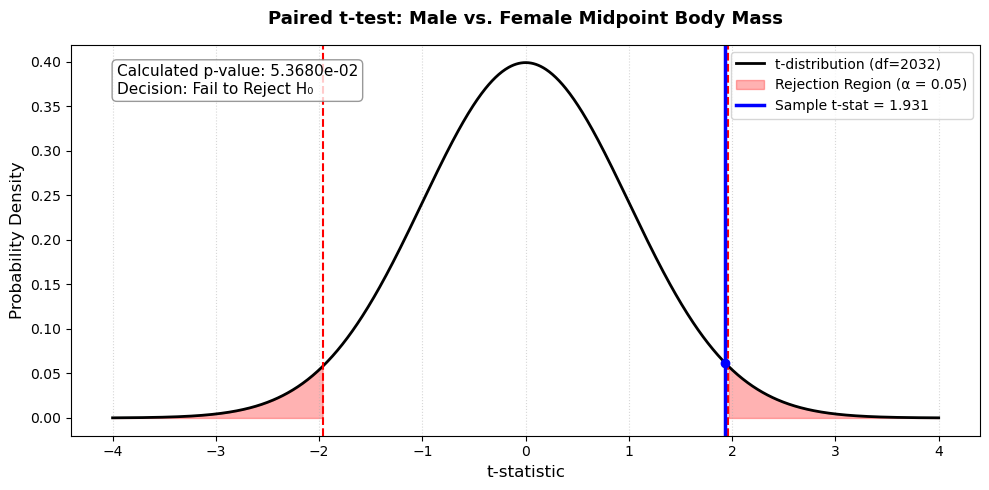

In [5]:
import matplotlib.pyplot as plt
import numpy as np

df_count = len(bm_clean_df) - 1

x_bound = max(4, abs(t_stat) + 1)
x = np.linspace(-x_bound, x_bound, 1000)
y = stats.t.pdf(x, df=df_count)
alpha = 0.05
t_crit_left = stats.t.ppf(alpha / 2, df=df_count)
t_crit_right = stats.t.ppf(1 - alpha / 2, df=df_count)

plt.figure(figsize=(10, 5))
plt.plot(x, y, color='black', linewidth=2, label=f't-distribution (df={df_count})')

plt.fill_between(x, y, where=(x <= t_crit_left), color='red', alpha=0.3, label='Rejection Region (α = 0.05)')
plt.fill_between(x, y, where=(x >= t_crit_right), color='red', alpha=0.3)
plt.axvline(t_crit_left, color='red', linestyle='--', linewidth=1.5)
plt.axvline(t_crit_right, color='red', linestyle='--', linewidth=1.5)

plt.axvline(t_stat, color='blue', linestyle='-', linewidth=2.5, label=f'Sample t-stat = {t_stat:.3f}')
plt.plot(t_stat, stats.t.pdf(t_stat, df=df_count), 'bo')
decision = "Reject H₀" if p_val < alpha else "Fail to Reject H₀"
text_str = f"Calculated p-value: {p_val:.4e}\nDecision: {decision}"
plt.gca().text(0.05, 0.95, text_str, transform=plt.gca().transAxes, fontsize=11,
               verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray'))
plt.title('Paired t-test: Male vs. Female Midpoint Body Mass', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('t-statistic', fontsize=12)
plt.ylabel('Probability Density', fontsize=12)
plt.legend(loc='upper right')
plt.grid(axis='x', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

We conduct a statistical test to compare the masses of male and female birds. Given that the dataset has "MinMass" and "MaxMass" of both sexes, we took the average of both columns to create "Midpoint" for each sex. We performed a two-sample t-test to determine if there was difference between the average mass of male and female birds. \
H0: Mean male mass = mean female mass\
Ha: mean male mass != mean female mass\
p-value = 0.05368 > 0.05 = alpha. Additionally, in the probability distribution graph, the test statistics, 1.93053, is out of the rejection region. Therefore, we fail to reject H0. There is insufficient evidence to suggest that the mean mass of male birds is different from the mean mass of female birds. \
This makes sense considering that half of bird species are monomorphic, meaning that males and females look nearly identical. As such, for half of bird species, males and females weigh nearly the same. 